# Harmonic offset for bi-exponential samples

The decay of every pixel arrives later than its IRF by an offset `t0(r)`.
Every pixel mixes a short `tau1` and a long `tau2`, with a photon fraction `A1` of the short component that changes from pixel to pixel.
On the phasor plot such pixels lie on the **chord** between the phasors of the two pure components, and the offset rotates the whole chord.

For a general decay the offset of a pixel cannot be identified -- only bracketed. 
Under the **bi-exponential model**, however, `K >= 3` harmonics give `2K` real numbers for four unknowns (`t0`, `tau1`, `tau2`, `A1`) per pixel, so the offset becomes identifiable from the bi-exponential pixels.

This example walks through:
- Simulating a bi-exponential two-well plate with a known offset that grows across the field
- What the offset does to the chord and to the fractions read off it
- The mono-exponential estimator on bi-exponential data: rejection, bias, and the bracket that still holds
- The bi-exponential harmonic estimator: offset map, lifetimes and fractions per pixel

<small>Author - Vikas</small>

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "ex_helper")

from sim_general_image import ROIMaskGenerator, WellPlateShape

from pyfli.data_vnp import ColorProcessor, DataViewer
from pyfli.io import DataOperations
from pyfli.laguerre import LaguerreFLI
from pyfli.phasor.harmonic_offset import HarmonicOffset, correct_phasors, t0_from_h_shift
from pyfli.phasor.phasorS import PhasorAnalyzer
from pyfli.reconstruction import ParamToDecay
from pyfli.reconstruction.common_reconstruct import gate_starts

In [2]:
# Path to the local IRF file
IRF_PATH = "<select file/folder path>"

In [3]:
rng = np.random.default_rng()

LASER_HZ = 80e6
PERIOD_NS = 1e9 / LASER_HZ

irf = np.clip(np.asarray(DataOperations(irf_path=IRF_PATH).load_irf(), dtype=float)[120, 40, :], 0.0, None)
irf /= irf.sum()
N_BINS = irf.size
DT = PERIOD_NS / N_BINS
t = gate_starts(PERIOD_NS, N_BINS)

INFO:pyfli:Initiating IRF load from: <select file/folder path>


## A bi-exponential two-well plate with a known offset

- Every pixel is bi-exponential with `tau1` = 0.6 ns and `tau2` = 3.0 ns. `A1` is drawn per pixel from a Beta distribution: mostly short in well 1 (mean 0.7), mostly long in well 2 (mean 0.3), with a wide spread.
- The decay of each pixel is delayed against the IRF by `h(r) = 0.20 + 0.25 x` ns, `x` running from 0 to 1 across the field.
- Exact expectation of PyFLI's periodic forward model (`ParamToDecay(..., shift_method="circular")`) with Poisson noise, about 2e4 photons per pixel, background 0.5 counts per bin.

Reconstructing decay (vectorized)...


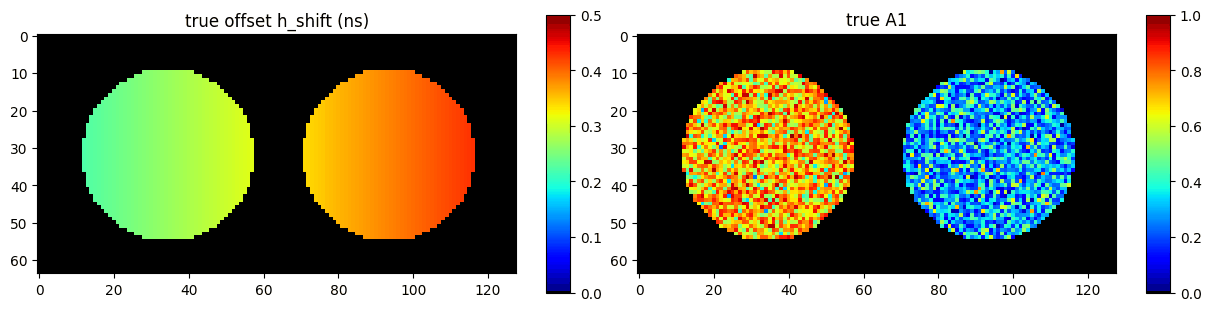

In [4]:
generator = ROIMaskGenerator((64, 128), top=5, bottom=5, left=5, right=5)
two_wells = WellPlateShape(rows=1, cols=2, gap=0.15)
img_cluster = generator.generate_cluster_mask(two_wells)
mask = generator.generate_binary_mask(two_wells).astype(bool)
H, W = mask.shape
well_names = {1: "well 1 (A1 ~ 0.7)", 2: "well 2 (A1 ~ 0.3)"}

TAU1, TAU2 = 0.6, 3.0
x = np.broadcast_to(np.linspace(0.0, 1.0, W), (H, W))
h_true = 0.20 + 0.25 * x

a1_true = np.where(img_cluster == 1, rng.beta(7, 3, (H, W)), rng.beta(3, 7, (H, W)))
truth = {
    "tau1_map": np.full((H, W), TAU1),
    "tau2_map": np.full((H, W), TAU2),
    "alpha1_map": a1_true,
    "photon_count_map": np.where(mask, rng.uniform(1.5e4, 2.5e4, (H, W)), 0.0),
    "v_shift_map": np.where(mask, 0.5, 0.0),
    "h_shift_map": h_true,
}
expected = ParamToDecay("bi-exponential", LASER_HZ / 1e6, irf, shift_method="circular").reconstruct_vectorized(truth)
decay = rng.poisson(np.where(mask[..., None], expected["fit_map"], 0.0)).astype(float)

jet_m = ColorProcessor().lowest_zero("jet")
_ = DataViewer().display_data(
    [np.where(mask, h_true, 0), np.where(mask, a1_true, 0)],
    structure=(1, 2),
    coord=None,
    data_names=["true offset h_shift (ns)", "true A1"],
    cmaps=[jet_m] * 2,
    v_ranges=[(0, 0.5), (0, 1)],
    figsize=(12, 3),
    normalize=False,
    yscale="linear",
)

## Standard phasor analysis: the offset rotates the chord

After IRF calibration the pixels should lie on the chord between the universal-semicircle phasors of `tau1` and `tau2` (dashed). The offset rotates them off it, and the photon fractions read off the chord (`PhasorAnalyzer.compute_fractions`) are biased.

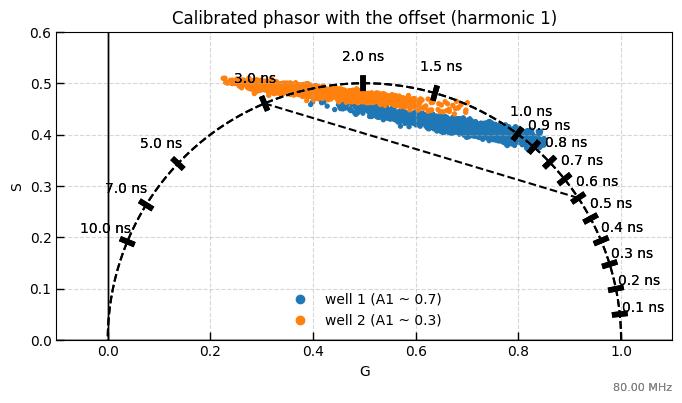

In [5]:
analyzer = PhasorAnalyzer(frequency_hz=LASER_HZ, time_axis_ns=t, n_harmonics=4)
G, S = analyzer.create_phasor_cpu(decay)
Gc, Sc = analyzer.calibrate(G, S, irf)
chord_g, chord_s = analyzer.lifetime_to_phasor(np.array([TAU1, TAU2]), LASER_HZ)

BLUE, ORANGE = (0.12, 0.47, 0.71), (1.0, 0.5, 0.05)


def solid(color):
    return np.broadcast_to(np.asarray(color), (*mask.shape, 3))


def phasor_plot(g, s, title):
    fig, ax = plt.subplots(figsize=(8, 4))
    analyzer.plot_phasor_diagram(g, s, mask=img_cluster == 1, colors=solid(BLUE), ax=ax)
    analyzer.plot_phasor_diagram(g, s, mask=img_cluster == 2, colors=solid(ORANGE), ax=ax, title=title)
    ax.plot(chord_g, chord_s, "k--", linewidth=1.5)
    ax.legend(
        handles=[plt.Line2D([], [], marker="o", linestyle="", color=c, label=n) for c, n in [(BLUE, well_names[1]), (ORANGE, well_names[2])]],
        frameon=False, loc="lower center",
    )
    plt.show()


phasor_plot(Gc[0], Sc[0], "Calibrated phasor with the offset (harmonic 1)")

## The mono-exponential estimator on bi-exponential data

The default estimator assumes a mono-exponential decay: its per-harmonic estimate `t0_k` is exact only then, and for any other decay it is biased low by an amount that differs between harmonics. 
Its chi-square test therefore rejects almost every bi-exponential pixel; 
the few nearly-pure pixels it keeps still carry a low bias, so the offset surface fitted to them is too early. This is the correct behaviour -- the estimator does not invent a point estimate the model cannot support.

In [6]:
mono_model = HarmonicOffset(analyzer).estimate(decay, irf, order=1, v_shift=truth["v_shift_map"])
mono_error_ps = 1e3 * (mono_model["h_shift_map"] - h_true)
print(f"accepted as mono-exponential: {100 * mono_model['accepted'][mask].mean():.2f} % of the pixels")
print(f"offset error of the mono-exponential model: median {np.median(mono_error_ps[mask]):.1f} ps")

accepted as mono-exponential: 0.39 % of the pixels
offset error of the mono-exponential model: median -77.3 ps


pixels whose true offset lies inside the bracket: 99.9 %


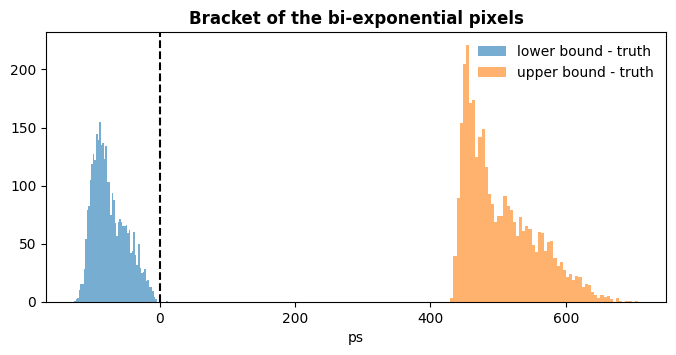

In [7]:
lower = mono_model["lower"] - t0_from_h_shift(h_true, t)
upper = mono_model["upper"] - t0_from_h_shift(h_true, t)
print(f"pixels whose true offset lies inside the bracket: {100 * ((lower <= 0) & (upper >= 0))[mask].mean():.1f} %")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(1e3 * lower[mask], bins=60, alpha=0.6, label="lower bound - truth")
ax.hist(1e3 * upper[mask], bins=60, alpha=0.6, label="upper bound - truth")
ax.axvline(0, color="k", linestyle="--")
ax.set_xlabel("ps")
ax.set_title("Bracket of the bi-exponential pixels", fontweight="bold")
ax.legend(frameon=False)
plt.show()

## The bi-exponential harmonic estimator

In [8]:
result = HarmonicOffset(analyzer).estimate(decay, irf, order=1, model="bi-exponential", v_shift=truth["v_shift_map"])
error_ps = 1e3 * (result["h_shift_map"] - h_true)
pixel_error_ps = 1e3 * (result["t0_hat"] - t0_from_h_shift(h_true, t))

pd.DataFrame(
    [
        {
            "estimator": name,
            "accepted (%)": 100 * res["accepted"][mask].mean(),
            "median h_shift error (ps)": np.median(1e3 * (res["h_shift_map"] - h_true)[mask]),
        }
        for name, res in [("mono-exponential model", mono_model), ("bi-exponential model", result)]
    ]
).set_index("estimator").round(2)

,accepted (%),median h_shift error (ps)
estimator,,
mono-exponential model,0.39,-77.26
bi-exponential model,94.97,-0.26


per-pixel offset: median error -0.2 ps, interquartile range 9.9 ps, median standard error 7.2 ps, median reduced chi2 0.83


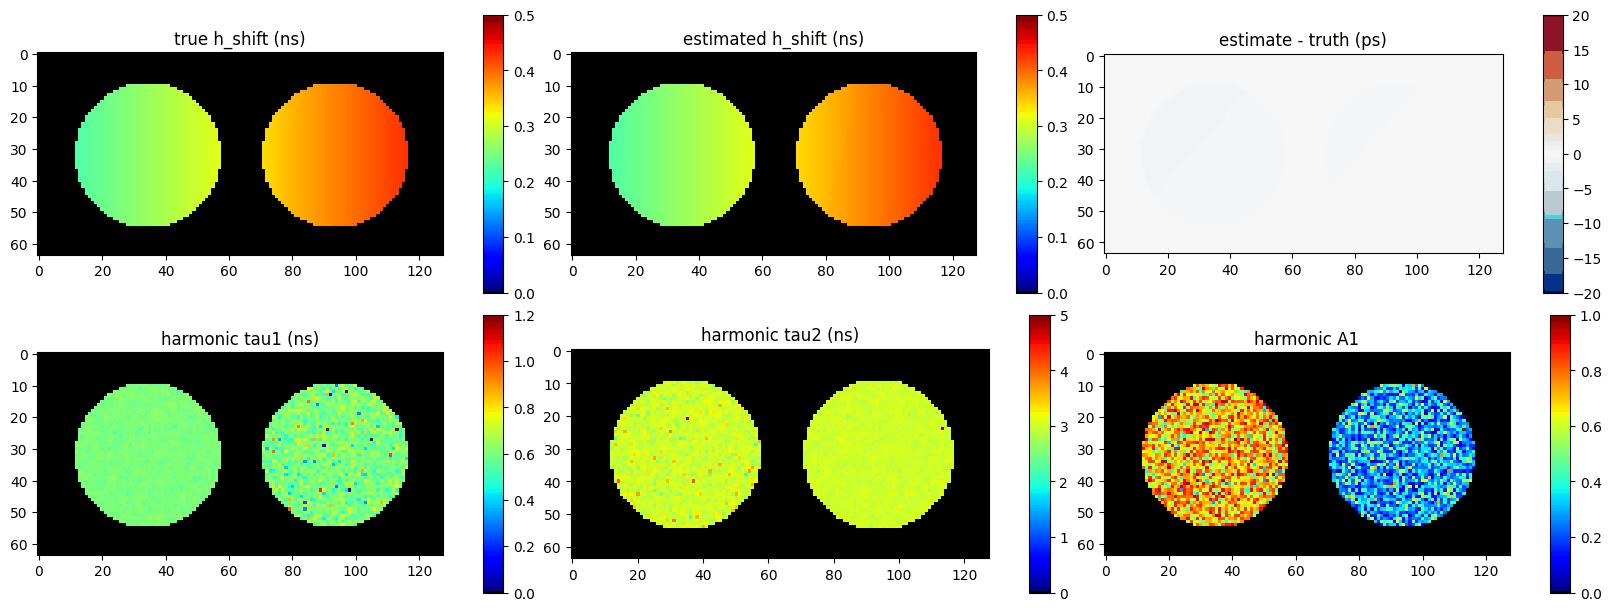

In [9]:
print(f"per-pixel offset: median error {np.nanmedian(pixel_error_ps[mask]):.1f} ps, "
      f"interquartile range {np.ptp(np.nanpercentile(pixel_error_ps[mask], [25, 75])):.1f} ps, "
      f"median standard error {1e3 * np.nanmedian(result['t0_se'][mask]):.1f} ps, "
      f"median reduced chi2 {np.nanmedian(result['reduced_chi2'][mask]):.2f}")

_ = DataViewer().display_data(
    [np.where(mask, h_true, 0), np.where(mask, result["h_shift_map"], 0), np.where(mask, error_ps, 0),
     np.where(mask, result["tau1_hat"], 0), np.where(mask, result["tau2_hat"], 0), np.where(mask, result["alpha1_hat"], 0)],
    structure=(2, 3),
    coord=None,
    data_names=["true h_shift (ns)", "estimated h_shift (ns)", "estimate - truth (ps)",
                "harmonic tau1 (ns)", "harmonic tau2 (ns)", "harmonic A1"],
    cmaps=[jet_m, jet_m, "RdBu_r", jet_m, jet_m, jet_m],
    v_ranges=[(0, 0.5), (0, 0.5), (-20, 20), (0, 1.2), (0, 5), (0, 1)],
    figsize=(16, 6),
    normalize=False,
    yscale="linear",
)

## Correcting the phasors and the fractions

The correction `correct_phasors` is exact for every decay, so the rotated chord comes back onto the universal-circle chord, and the fractions read off it agree with the truth.

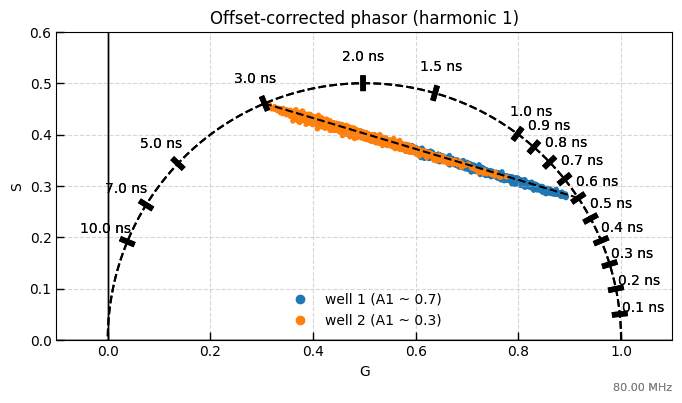

true median A1  chord median A1  \
phasor           well                                                 
before           well 1 (A1 ~ 0.7)           0.714            0.597   
                 well 2 (A1 ~ 0.3)           0.285            0.126   
after correction well 1 (A1 ~ 0.7)           0.714            0.707   
                 well 2 (A1 ~ 0.3)           0.285            0.283   

                                    median A1 error  
phasor           well                                
before           well 1 (A1 ~ 0.7)           -0.114  
                 well 2 (A1 ~ 0.3)           -0.158  
after correction well 1 (A1 ~ 0.7)           -0.007  
                 well 2 (A1 ~ 0.3)           -0.003

In [10]:
Gk, Sk = correct_phasors(Gc, Sc, result["t0_map"], LASER_HZ)
phasor_plot(Gk[0], Sk[0], "Offset-corrected phasor (harmonic 1)")

rows = []
for name, (g, s) in {"before": (Gc[0], Sc[0]), "after correction": (Gk[0], Sk[0])}.items():
    a1_est, _ = analyzer.compute_fractions(g, s, TAU1, TAU2, plot_graph=False)
    for cid, well in well_names.items():
        sel = img_cluster == cid
        rows.append({"phasor": name, "well": well, "true median A1": np.median(a1_true[sel]),
                     "chord median A1": np.median(a1_est[sel]), "median A1 error": np.median((a1_est - a1_true)[sel])})
pd.DataFrame(rows).set_index(["phasor", "well"]).round(3)